In [1]:
import pandas as pd
import loguru as logging
from PIL import Image
import numpy as np

### Initial loading and merging of datasets

In [2]:
mapping = pd.read_csv(r"D:\galaxy classification\data\raw\mapping.csv")
labels = pd.read_csv(r"D:\galaxy classification\data\raw\labels.csv")

In [3]:
merge = pd.merge(mapping, labels, left_on='objid', right_on='dr7objid')
merge.head()

,objid,sample_x,asset_id,dr7objid,ra,dec,rastring,decstring,sample_y,gz2_class,...,t11_arms_number_a36_more_than_4_fraction,t11_arms_number_a36_more_than_4_weighted_fraction,t11_arms_number_a36_more_than_4_debiased,t11_arms_number_a36_more_than_4_flag,t11_arms_number_a37_cant_tell_count,t11_arms_number_a37_cant_tell_weight,t11_arms_number_a37_cant_tell_fraction,t11_arms_number_a37_cant_tell_weighted_fraction,t11_arms_number_a37_cant_tell_debiased,t11_arms_number_a37_cant_tell_flag
0,587722981741363294,original,3,587722981741363294,182.925262,-1.092357,12:11:42.06,-01:05:32.5,original,Sb,...,0.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0
1,587722981741363323,original,4,587722981741363323,182.970108,-1.219537,12:11:52.83,-01:13:10.3,original,Sc?l,...,0.0,0.0,0.0,0,1,1.0,1.0,1.0,1.0,1
2,587722981741559888,original,5,587722981741559888,183.438095,-1.238414,12:13:45.14,-01:14:18.3,original,Er,...,0.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0
3,587722981741625481,original,6,587722981741625481,183.473999,-1.231429,12:13:53.76,-01:13:53.1,original,Sc1t,...,0.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0
4,587722981741625484,original,7,587722981741625484,183.477783,-1.084604,12:13:54.67,-01:05:04.6,original,Sb,...,0.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0


In [4]:
merge["gz2_class"].value_counts()

gz2_class
Ei          44038
Er          36764
Ser         14009
Sc?t        13509
Ec          10149
            ...  
Sd1t(o)         1
SBc4m(m)        1
SBd?t(r)        1
SBc1t(u)        1
SBd+m(i)        1
Name: count, Length: 818, dtype: int64

### Filtering diebiased data and also making viewable function


In [5]:
dir = r"D:\galaxy classification\images"

def load_image(id):
    img_path = f"{dir}/{id}.jpg"
    img = Image.open(img_path).convert('RGB')
    return img


In [6]:
debiased_df = merge[["objid","asset_id","sample_x","total_votes"]+[col for col in merge.columns if col.endswith('_debiased')]]
debiased_df

,objid,asset_id,sample_x,total_votes,t01_smooth_or_features_a01_smooth_debiased,t01_smooth_or_features_a02_features_or_disk_debiased,t01_smooth_or_features_a03_star_or_artifact_debiased,t02_edgeon_a04_yes_debiased,t02_edgeon_a05_no_debiased,t03_bar_a06_bar_debiased,...,t09_bulge_shape_a27_no_bulge_debiased,t10_arms_winding_a28_tight_debiased,t10_arms_winding_a29_medium_debiased,t10_arms_winding_a30_loose_debiased,t11_arms_number_a31_1_debiased,t11_arms_number_a32_2_debiased,t11_arms_number_a33_3_debiased,t11_arms_number_a34_4_debiased,t11_arms_number_a36_more_than_4_debiased,t11_arms_number_a37_cant_tell_debiased
0,587722981741363294,3,original,181,0.459,0.681,0.000,0.041914,0.914402,0.000000,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
1,587722981741363323,4,original,111,0.216,0.736,0.000,0.000000,1.000000,0.376434,...,0.00000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,1.000000
2,587722981741559888,5,original,153,0.773,0.029,0.114,0.000000,1.000000,0.000000,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
3,587722981741625481,6,original,136,0.152,0.639,0.009,0.000000,1.000000,0.000000,...,0.00000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.00000,0.000000,0.000000
4,587722981741625484,7,original,150,0.182,0.720,0.032,0.000000,1.000000,0.000000,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
239690,588015510368681992,295294,stripe82,273,0.000,1.000,0.000,0.000000,1.000000,0.912724,...,0.00000,0.395750,0.516223,0.080662,0.000000,0.068418,0.058680,0.50517,0.419035,0.029496
239691,588015510368682105,295295,stripe82,149,0.800,0.146,0.073,0.126668,0.836558,0.000000,...,0.00000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,1.000000
239692,588015510368682132,295296,stripe82,138,0.733,0.190,0.022,0.861468,0.232142,0.000000,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
239693,588015510636265643,295304,stripe82,213,0.089,0.892,0.010,0.343208,0.668841,0.228637,...,0.58578,0.313458,0.266263,0.361677,0.075168,0.115436,0.000000,0.00000,0.000000,0.692101


In [7]:
debiased_df.columns[debiased_df.columns.str.contains("t07")].value_counts()

t07_rounded_a16_completely_round_debiased    1
t07_rounded_a17_in_between_debiased          1
t07_rounded_a18_cigar_shaped_debiased        1
Name: count, dtype: int64

## Method 1 
Using thresholds for galaxy classification based on voting by [Zhu et al., 2019](https://arxiv.org/abs/1807.10406)

| Class | CleanSample | Tasks | T01 | T01_Label | T01_Val | T07 | T07_Label | T07_Val |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | Completelyroundsmooth | T01 | 8434 | fsmooth | 0.469 | 1 | fcompletely round | 0.50 |
| 1 | In-betweensmooth | T01 | 8069 | fsmooth | 0.469 | 2 | fbetween | 0.50 |
| 2 | Cigar-shaped smooth | T01 | 578 | fsmooth | 0.469 | 3 | fcigar shaped | 0.50 |
| 3 | Edge-on | T01 | 3903 | ffeaturesdisk | 0.430 | T02 | fedge onyes | 0.602 |
| 4 | Spiral | T02 | 7806 | fedge onno | 0.715 |  |  |  |

In [8]:
debiased_df = debiased_df[debiased_df["total_votes"] > 50] #reccomended by the paper

<Axes: >

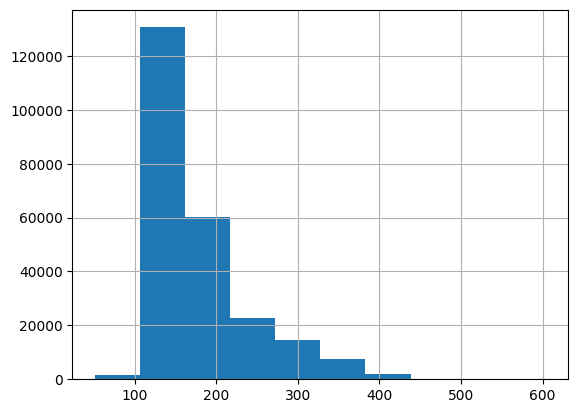

In [9]:
debiased_df["total_votes"].hist(bins=10)

In [10]:
f_smooth = 0.469
f_completely_round = 0.500
f_in_between = 0.500      #initializing thresholds
f_cigar_shaped = 0.500
f_faturesdisk = 0.430
f_edge_onyes = 0.602
f_edge_onno = 0.715
f_spiral_yes = 0.619

### Filtering for smooth and completely round galaxies

In [11]:
f_smooth_mask = debiased_df.columns.str.startswith('t01') & debiased_df.columns.str.endswith('smooth_debiased') #selecting right columns mask
f_completely_round_mask = debiased_df.columns.str.startswith('t07') & debiased_df.columns.str.endswith('completely_round_debiased')

smooth_cols = debiased_df.columns[f_smooth_mask].tolist() #selecting the column with the mask
completely_round_cols = debiased_df.columns[f_completely_round_mask].tolist()

print('Smooth columns:', smooth_cols)
print('Completely round columns:', completely_round_cols)

Smooth columns: ['t01_smooth_or_features_a01_smooth_debiased']
Completely round columns: ['t07_rounded_a16_completely_round_debiased']


array([[<Axes: title={'center': 't07_rounded_a16_completely_round_debiased'}>,
        <Axes: title={'center': 't01_smooth_or_features_a01_smooth_debiased'}>]],
      dtype=object)

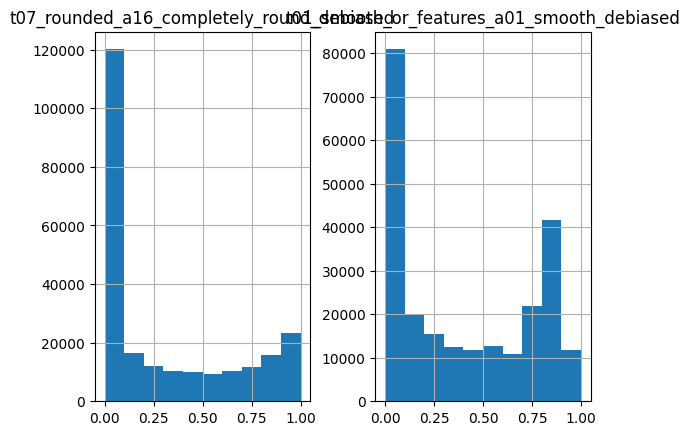

In [12]:
debiased_df[completely_round_cols+smooth_cols].hist()

In [13]:
mask = (debiased_df[smooth_cols] >= f_smooth).any(axis=1) & (debiased_df[completely_round_cols] >= f_completely_round).any(axis=1) #mask to filter the data
smooth_completely_round_df = debiased_df[mask].dropna()#filtering the data

array([[<Axes: title={'center': 't01_smooth_or_features_a01_smooth_debiased'}>,
        <Axes: title={'center': 't07_rounded_a16_completely_round_debiased'}>]],
      dtype=object)

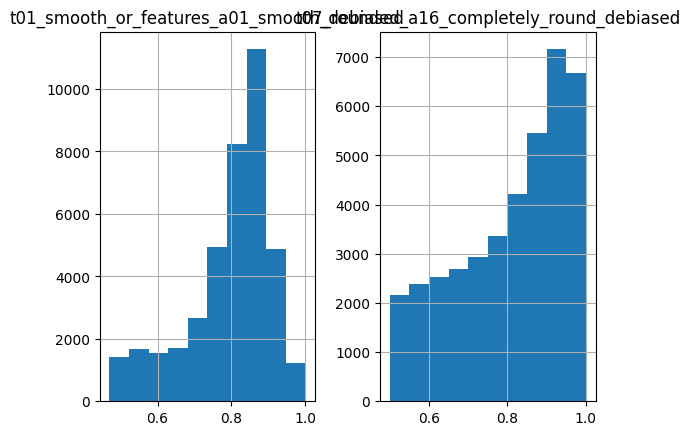

In [14]:
smooth_completely_round_df[smooth_cols + completely_round_cols].hist()

### Filtering In-between smooth galaxies

In [15]:
f_in_between_mask = debiased_df.columns.str.startswith('t07') & debiased_df.columns.str.endswith('in_between_debiased')

in_between_cols = debiased_df.columns[f_in_between_mask].tolist()

print('In-between columns:', in_between_cols)

In-between columns: ['t07_rounded_a17_in_between_debiased']


In [16]:
mask1 = (debiased_df[smooth_cols] >= f_smooth).any(axis=1) & (debiased_df[in_between_cols] >= f_in_between).any(axis=1)
in_between_smooth_df = debiased_df[mask1].dropna()

array([[<Axes: title={'center': 't01_smooth_or_features_a01_smooth_debiased'}>,
        <Axes: title={'center': 't07_rounded_a17_in_between_debiased'}>]],
      dtype=object)

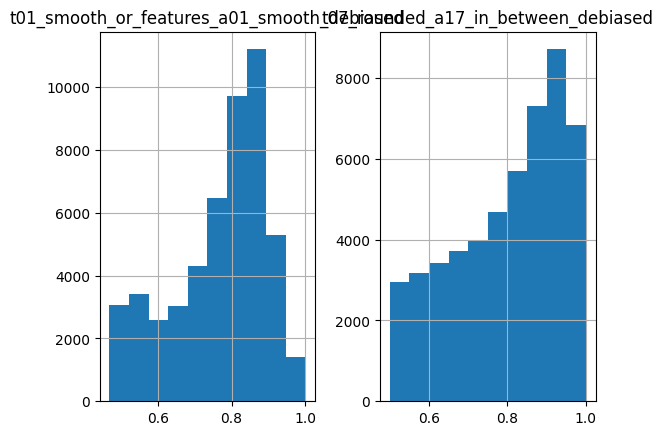

In [17]:
in_between_smooth_df[smooth_cols + in_between_cols].hist()

In [18]:
common_inbetwee_and_completly_smooth = pd.merge(in_between_smooth_df, smooth_completely_round_df, on='objid', how='inner') #join to find common

#### Cigar Shaped Smooth

In [19]:
cigar_shaped_mask = debiased_df.columns.str.startswith('t07') & debiased_df.columns.str.endswith('cigar_shaped_debiased')
cigar_shaped_cols = debiased_df.columns[cigar_shaped_mask].tolist()
mask2 = (debiased_df[cigar_shaped_cols] >= f_cigar_shaped).any(axis=1) & (debiased_df[smooth_cols] >= f_smooth).any(axis=1)
cigar_shaped_df = debiased_df[mask2].dropna()

In [20]:
cigar_shaped_df.shape

(15474, 41)

#### Edge-on

In [21]:
edge_on_yes_mask = debiased_df.columns.str.startswith('t02') & debiased_df.columns.str.endswith('yes_debiased')
edge_on_yes_cols = debiased_df.columns[edge_on_yes_mask].tolist()

feature_disk_mask = debiased_df.columns.str.startswith('t01') & debiased_df.columns.str.endswith('features_or_disk_debiased')
feature_disk_cols = debiased_df.columns[feature_disk_mask].tolist()

mask3 = (debiased_df[edge_on_yes_cols] >= f_edge_onyes).any(axis=1) & (debiased_df[feature_disk_cols] >= f_faturesdisk).any(axis=1)
edge_on_yes_df = debiased_df[mask3].dropna()




#### sprial

In [22]:
edge_on_no_mask = debiased_df.columns.str.startswith('t02') & debiased_df.columns.str.endswith('no_debiased')
edge_on_no_cols = debiased_df.columns[edge_on_no_mask].tolist()

spiral_yes_mask = debiased_df.columns.str.startswith('t04') & debiased_df.columns.str.endswith('spiral_debiased')
spiral_yes_cols = debiased_df.columns[spiral_yes_mask].tolist()

mask4 = (debiased_df[edge_on_no_cols] >= f_edge_onno).any(axis=1) & (debiased_df[spiral_yes_cols] >= f_spiral_yes).any(axis=1) \
        & (debiased_df[feature_disk_cols] >= f_faturesdisk).any(axis=1)

spiral_yes_df = debiased_df[mask4].dropna()

#### counts

In [23]:
import matplotlib.pyplot as plt

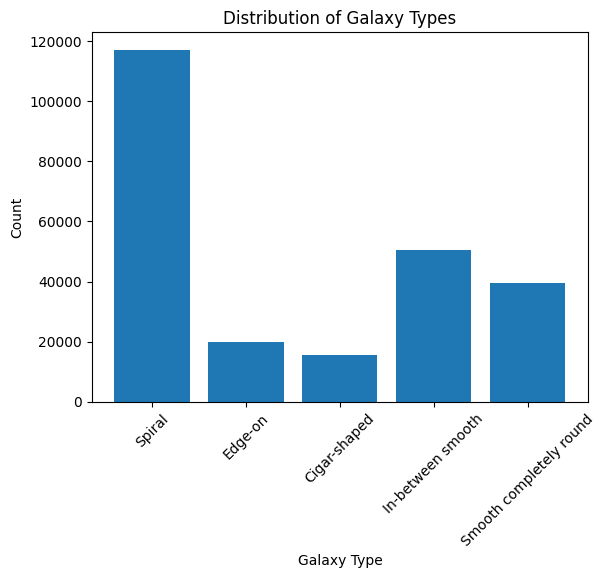

In [24]:
spiral_yes_df.shape[0]

count = [spiral_yes_df.shape[0], edge_on_yes_df.shape[0], cigar_shaped_df.shape[0], in_between_smooth_df.shape[0], smooth_completely_round_df.shape[0]]
labels = ['Spiral', 'Edge-on', 'Cigar-shaped', 'In-between smooth', 'Smooth completely round']
plt.bar(labels, count)
plt.xlabel('Galaxy Type')
plt.ylabel('Count')
plt.title('Distribution of Galaxy Types')
plt.xticks(rotation=45)
plt.show()

d:\galaxy classification\.venv\Lib\site-packages\upsetplot\data.py:303: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


<Figure size 1000x500 with 0 Axes>

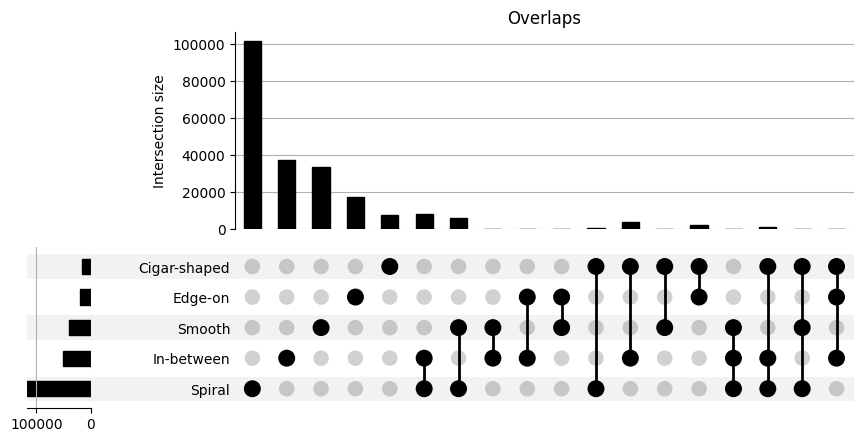

In [25]:
from matplotlib import pyplot as plt
from upsetplot import from_memberships, plot as upsetplot
from collections import Counter

sets = {
    'Spiral': set(spiral_yes_df['objid']),
    'Edge-on': set(edge_on_yes_df['objid']),
    'Cigar-shaped': set(cigar_shaped_df['objid']),
    'In-between': set(in_between_smooth_df['objid']),
    'Smooth': set(smooth_completely_round_df['objid']),
}

all_ids = set().union(*sets.values())
memberships_raw = []
for oid in sorted(all_ids):
    cats = [name for name,s in sets.items() if oid in s]
    memberships_raw.append(tuple(sorted(cats)))

counter = Counter(memberships_raw)
memberships = [list(k) for k in counter.keys()]
counts = list(counter.values())

up = from_memberships(memberships, data=counts)
plt.figure(figsize=(10,5))
upsetplot(up)
plt.title('Overlaps')
plt.show()

### High overlap
High overlap between differnt classes. As many galaxies are classified as both edge-on and spiral, we can use the following thresholds to filter the data for better classification. Since the filtering is done independently mutually exclusive classes are not possible. Thus falling to a better classficatoin method. 

In [26]:
smooth_col       = debiased_df.columns[debiased_df.columns.str.startswith('t01') & debiased_df.columns.str.endswith('smooth_debiased')][0]
features_col     = debiased_df.columns[debiased_df.columns.str.startswith('t01') & debiased_df.columns.str.endswith('features_or_disk_debiased')][0]
edge_yes_col     = debiased_df.columns[debiased_df.columns.str.startswith('t02') & debiased_df.columns.str.endswith('yes_debiased')][0]
edge_no_col      = debiased_df.columns[debiased_df.columns.str.startswith('t02') & debiased_df.columns.str.endswith('no_debiased')][0]
spiral_col       = debiased_df.columns[debiased_df.columns.str.startswith('t04') & debiased_df.columns.str.endswith('spiral_debiased')][0]
round_col        = debiased_df.columns[debiased_df.columns.str.startswith('t07') & debiased_df.columns.str.endswith('completely_round_debiased')][0]
inbet_col        = debiased_df.columns[debiased_df.columns.str.startswith('t07') & debiased_df.columns.str.endswith('in_between_debiased')][0]
cigar_col        = debiased_df.columns[debiased_df.columns.str.startswith('t07') & debiased_df.columns.str.endswith('cigar_shaped_debiased')][0]

CLASS_NAMES = {
    0: "completely_round_smooth",
    1: "in_between_smooth",
    2: "cigar_shaped_smooth",
    3: "edge_on",
    4: "spiral",
}


Using feature_disk < 0.43 and edge_on_yes > 0.602 for edge-on galaxies and edge_on_no > 0.715 for spiral galaxies, we can filter the data to get better classification results. Laslty usin argmax on overlaps

In [27]:
def assign_label(row) -> int | None:
    s  = row[smooth_col]
    fd = row[features_col]

    if s >= 0.469 and fd < 0.430:#threshold 1/ resolution of main overlaps
        t07 = {0: row[round_col], 1: row[inbet_col], 2: row[cigar_col]}
        best_cls, best_val = max(t07.items(), key=lambda x: x[1]) #argmax selection for voting selection
        if best_val >= 0.50:
            return best_cls
        return None  # T07 too ambiguous

    elif fd >= 0.430 and s < 0.469:
        if row[edge_yes_col] >= 0.602:
            return 3  # Edge on
        if row[edge_no_col] >= 0.715 and row[spiral_col] >= 0.619:
            return 4  # Spiral
        return None  # disk but ambiguous structure

    return None #didnt meet any criteria


In [28]:
df = debiased_df.copy()
df["label"] = df.apply(assign_label, axis=1)
total   = len(df)
labeled = df["label"].notna().sum()
dropped = total - labeled
percentage_dropped = (dropped / total) * 100
print(f"Total samples: {total}")
print(f"Labeled samples: {labeled}")
print(f"Dropped samples: {dropped}")
print(f"Percentage dropped: {percentage_dropped:.2f}%")


Total samples: 239666
Labeled samples: 182505
Dropped samples: 57161
Percentage dropped: 23.85%


About 23% of data was dropped due to unambiguous classifications. Thus even though this method of hard coding mutually exclusive classes is not ideal, it is the easiset way of prediction. I also plan to use voting prediction in future which is method 3 in this project. 

In [29]:
labeled_df = (
    df
    .dropna(subset=["label"])
    .assign(label=lambda d: d["label"].astype(int))
    .reset_index(drop=True)
)

([0, 1, 2, 3, 4],
 [Text(0, 0, 'completely_round_smooth'),
  Text(1, 0, 'in_between_smooth'),
  Text(2, 0, 'cigar_shaped_smooth'),
  Text(3, 0, 'edge_on'),
  Text(4, 0, 'spiral')])

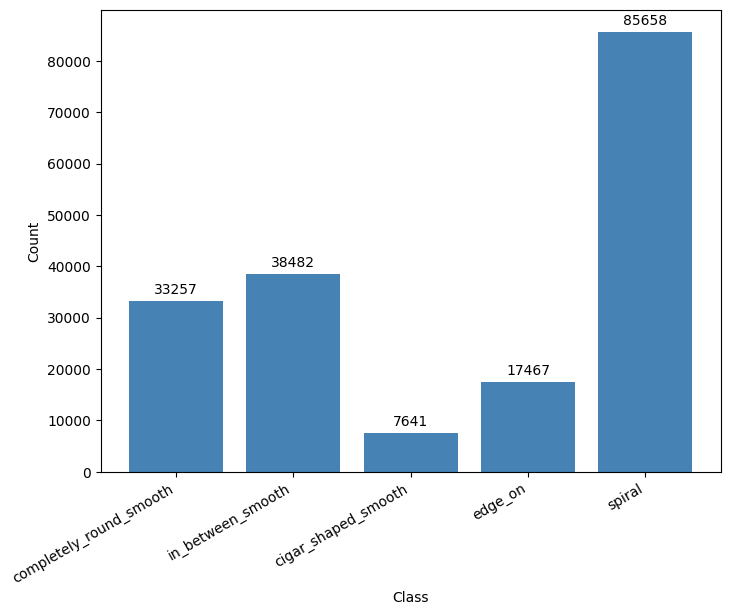

In [34]:
fig,ax = plt.subplots(figsize=(8, 6))
bars = ax.bar([CLASS_NAMES[i] for i in counts.index], counts.values, color='steelblue')
ax.bar_label(bars, labels=counts.values, padding=3)
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(rotation=30, ha='right')
